# Electric Vehicle Data Analysis

# 1. Importing Required Libraries

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('ggplot')
sns.set(font_scale=1)

print("Libraries Imported Successfully")

Libraries Imported Successfully


# 2. Loading and Previewing the Raw Dataset

In [2]:
path = r"C:\Users\User\Desktop\Data-Analyst-Portfolio\Electric-Vehicle-Analysis\Dataset\Raw\export.csv"

df = pd.read_csv(path)

print("Dataset Loaded Successfully")

df.head()

Dataset Loaded Successfully


,VIN (1-10),County,City,State,Postal Code,Model Year,Make,Model,Electric Vehicle Type,Clean Alternative Fuel Vehicle (CAFV) Eligibility,Electric Range,Legislative District,DOL Vehicle ID,Vehicle Location,Electric Utility,2020 Census Tract
0,5UX43EU07S,Snohomish,Snohomish,WA,98296.0,2025,BMW,X5,Plug-in Hybrid Electric Vehicle (PHEV),Clean Alternative Fuel Vehicle Eligible,40.0,44.0,279314360,POINT (-122.1389 47.87115),PUGET SOUND ENERGY INC,5.306105e+10
1,5YJ3E1EB5J,Yakima,Yakima,WA,98901.0,2018,TESLA,MODEL 3,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,215.0,14.0,220635992,POINT (-120.50729 46.60464),PACIFICORP,5.307700e+10
2,WA1AAAGE5M,King,Seattle,WA,98112.0,2021,AUDI,E-TRON,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,222.0,43.0,282112967,POINT (-122.30207 47.64085),CITY OF SEATTLE - (WA)|CITY OF TACOMA - (WA),5.303301e+10
3,5YJXCAE2XG,Kitsap,Bremerton,WA,98310.0,2016,TESLA,MODEL X,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,200.0,23.0,103165100,POINT (-122.61136 47.5752),PUGET SOUND ENERGY INC,5.303508e+10
4,5YJ3E1EB5J,Yakima,Yakima,WA,98908.0,2018,TESLA,MODEL 3,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,215.0,14.0,301024209,POINT (-120.60272 46.59656),PACIFICORP,5.307700e+10


# 3. Understanding Dataset Structure and Dimensions

In [3]:
print("Rows :", df.shape[0])
print("Columns :", df.shape[1])

df.info()

Rows : 289564
Columns : 16
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 289564 entries, 0 to 289563
Data columns (total 16 columns):
 #   Column                                             Non-Null Count   Dtype  
---  ------                                             --------------   -----  
 0   VIN (1-10)                                         289564 non-null  object 
 1   County                                             289555 non-null  object 
 2   City                                               289555 non-null  object 
 3   State                                              289564 non-null  object 
 4   Postal Code                                        289555 non-null  float64
 5   Model Year                                         289564 non-null  int64  
 6   Make                                               289564 non-null  object 
 7   Model                                              289564 non-null  object 
 8   Electric Vehicle Type                          

In [4]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
VIN (1-10),289564,17883,7SAYGDEE6P,1196,NaN,NaN,NaN,NaN,NaN,NaN,NaN
County,289555,249,King,140130,NaN,NaN,NaN,NaN,NaN,NaN,NaN
City,289555,920,Seattle,44333,NaN,NaN,NaN,NaN,NaN,NaN,NaN
State,289564,53,WA,288838,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Postal Code,289555.0,NaN,NaN,NaN,98179.343375,2595.46598,1030.0,98052.0,98133.0,98388.0,99801.0
Model Year,289564.0,NaN,NaN,NaN,2022.255957,3.080426,1999.0,2021.0,2023.0,2024.0,2027.0
Make,289564,49,TESLA,118148,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Model,289564,198,MODEL Y,62979,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Electric Vehicle Type,289564,2,Battery Electric Vehicle (BEV),233544,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Clean Alternative Fuel Vehicle (CAFV) Eligibility,289564,3,Eligibility unknown as battery range has not b...,188456,NaN,NaN,NaN,NaN,NaN,NaN,NaN


# Data Cleaning
# 4. Identifying Missing Values

In [5]:
missing = df.isnull().sum()

missing = missing[missing > 0].sort_values(ascending=False)

print("Columns with Missing Values:")
print(missing)

Columns with Missing Values:
Legislative District    727
Vehicle Location         16
Electric Range           10
County                    9
Postal Code               9
City                      9
Electric Utility          9
2020 Census Tract         9
dtype: int64


# 5. Checking for Duplicate Records

In [6]:
duplicates = df.duplicated().sum()

print("Duplicate Records:", duplicates)

Duplicate Records: 0


# 6. Checking Missing and Zero Electric Range Values

In [7]:
missing_range = df['Electric Range'].isnull().sum()
zero_range = (df['Electric Range'] == 0).sum()

print("Missing Electric Range:", missing_range)
print("Zero Electric Range:", zero_range)

Missing Electric Range: 10
Zero Electric Range: 188456


# 7. Checking Base MSRP Column Availability

In [8]:
if 'Base MSRP' in df.columns:
    print("Base MSRP column is available.")
    print("Missing Base MSRP:", df['Base MSRP'].isnull().sum())
    print("Zero Base MSRP:", (df['Base MSRP'] == 0).sum())
else:
    print("Base MSRP column is not available in this dataset.")

Base MSRP column is not available in this dataset.


# 8. Handling Missing Electric Range Values

In [9]:
electric_range_median = df['Electric Range'].median()

df['Electric Range'] = df['Electric Range'].fillna(electric_range_median)

print("Missing Electric Range after treatment:",
      df['Electric Range'].isnull().sum())

print("Electric Range median used:",
      electric_range_median)

Missing Electric Range after treatment: 0
Electric Range median used: 0.0


# 9. Analyzing Electric Range by Vehicle Type

In [10]:
range_by_type = (
    df.groupby('Electric Vehicle Type')['Electric Range']
      .agg(['count', 'mean', 'median'])
)

range_by_type

,count,mean,median
Electric Vehicle Type,,,
Battery Electric Vehicle (BEV),233544,38.668846,0.0
Plug-in Hybrid Electric Vehicle (PHEV),56020,32.102392,32.0


# 10. Handling Remaining Missing Values

In [11]:
# Fill categorical columns with 'Unknown'
categorical_cols = [
    'County',
    'City',
    'Vehicle Location',
    'Electric Utility'
]

for col in categorical_cols:
    df[col] = df[col].fillna('Unknown')

# Fill numeric columns with their median
numeric_cols = [
    'Postal Code',
    'Legislative District',
    '2020 Census Tract'
]

for col in numeric_cols:
    df[col] = df[col].fillna(df[col].median())

print("Remaining Missing Values:")
print(df.isnull().sum())

Remaining Missing Values:
VIN (1-10)                                           0
County                                               0
City                                                 0
State                                                0
Postal Code                                          0
Model Year                                           0
Make                                                 0
Model                                                0
Electric Vehicle Type                                0
Clean Alternative Fuel Vehicle (CAFV) Eligibility    0
Electric Range                                       0
Legislative District                                 0
DOL Vehicle ID                                       0
Vehicle Location                                     0
Electric Utility                                     0
2020 Census Tract                                    0
dtype: int64


# 11. Verifying Duplicate Records After Cleaning

In [12]:
duplicates_after = df.duplicated().sum()

print("Duplicate Records After Cleaning:", duplicates_after)

Duplicate Records After Cleaning: 0


# 12. Anonymizing Vehicle Identification Numbers

In [13]:
df['VIN_Anonymized'] = pd.factorize(df['VIN (1-10)'])[0] + 1

print("VIN anonymization completed.")

df[['VIN (1-10)', 'VIN_Anonymized']].head()

VIN anonymization completed.


,VIN (1-10),VIN_Anonymized
0,5UX43EU07S,1
1,5YJ3E1EB5J,2
2,WA1AAAGE5M,3
3,5YJXCAE2XG,4
4,5YJ3E1EB5J,2


# 13. Inspecting Vehicle Location Data

In [14]:
print(df['Vehicle Location'].head(10))
print("\nData Type:", df['Vehicle Location'].dtype)

0     POINT (-122.1389 47.87115)
1    POINT (-120.50729 46.60464)
2    POINT (-122.30207 47.64085)
3     POINT (-122.61136 47.5752)
4    POINT (-120.60272 46.59656)
5    POINT (-120.51904 46.59782)
6     POINT (-122.63848 47.5414)
7    POINT (-122.65223 47.57192)
8    POINT (-122.34731 47.45207)
9    POINT (-122.64681 47.73689)
Name: Vehicle Location, dtype: object

Data Type: object


# 14. Extracting Latitude and Longitude from Vehicle Locations

In [15]:
df['Longitude'] = df['Vehicle Location'].str.extract(
    r'POINT \(([-\d.]+) [-\d.]+\)'
).astype(float)

df['Latitude'] = df['Vehicle Location'].str.extract(
    r'POINT \([-\d.]+ ([-\d.]+)\)'
).astype(float)

print("Latitude and Longitude extracted successfully.")

df[['Vehicle Location', 'Latitude', 'Longitude']].head()

Latitude and Longitude extracted successfully.


,Vehicle Location,Latitude,Longitude
0,POINT (-122.1389 47.87115),47.87115,-122.13890
1,POINT (-120.50729 46.60464),46.60464,-120.50729
2,POINT (-122.30207 47.64085),47.64085,-122.30207
3,POINT (-122.61136 47.5752),47.57520,-122.61136
4,POINT (-120.60272 46.59656),46.59656,-120.60272


# 15. Identifying the Top 5 EV Manufacturers

In [16]:
top_makes = df['Make'].value_counts().head(5)

print("Top 5 EV Manufacturers:")
print(top_makes)

Top 5 EV Manufacturers:
Make
TESLA        118148
CHEVROLET     19808
NISSAN        16023
FORD          15930
KIA           14501
Name: count, dtype: int64


# 16. Identifying the Top 5 EV Models

In [18]:
top_models = df['Model'].value_counts().head(5)

print("Top 5 EV Models:")
print(top_models)

Top 5 EV Models:
Model
MODEL Y    62979
MODEL 3    38325
LEAF       13406
MODEL S     7784
BOLT EV     7518
Name: count, dtype: int64


# 17. Analyzing EV Registrations by County

In [35]:
county_counts = df['County'].value_counts()

print("Top 10 Counties by EV Registrations:")
print(county_counts.head(10))

print("\nCounty with Most EV Registrations:")
print(county_counts.idxmax())

print("Number of Registrations:")
print(county_counts.max())

Top 10 Counties by EV Registrations:
County
King         140130
Snohomish     36508
Pierce        24162
Clark         18060
Thurston      10617
Kitsap        10023
Spokane        8329
Whatcom        7205
Benton         4304
Skagit         3440
Name: count, dtype: int64

County with Most EV Registrations:
King
Number of Registrations:
140130


# 18. Analyzing EV Adoption by Model Year

In [22]:
year = df['Model Year'].value_counts().sort_index()

print(year)

Model Year
1999        2
2000        7
2002        1
2003        1
2008       17
2010       21
2011      532
2012     1301
2013     3831
2014     3107
2015     4343
2016     5025
2017     8341
2018    13926
2019    10677
2020    11927
2021    20608
2022    29937
2023    60332
2024    49277
2025    37044
2026    29058
2027      249
Name: count, dtype: int64


# 19. Calculating Average Electric Range

In [56]:
average_range = df['Electric Range'].mean()

print("Average Electric Range:", round(average_range, 2), "miles")

Average Electric Range: 37.4 miles


# 20. Analyzing CAFV Eligibility Distribution

In [25]:
cafv = df['Clean Alternative Fuel Vehicle (CAFV) Eligibility'].value_counts()

print(cafv)

print("\nCAFV Percentage:")
print((cafv / len(df) * 100).round(2))

Clean Alternative Fuel Vehicle (CAFV) Eligibility
Eligibility unknown as battery range has not been researched    188456
Clean Alternative Fuel Vehicle Eligible                          77580
Not eligible due to low battery range                            23528
Name: count, dtype: int64

CAFV Percentage:
Clean Alternative Fuel Vehicle (CAFV) Eligibility
Eligibility unknown as battery range has not been researched    65.08
Clean Alternative Fuel Vehicle Eligible                         26.79
Not eligible due to low battery range                            8.13
Name: count, dtype: float64


# 21. Analyzing Average Electric Range by Manufacturer

In [27]:
range_make = df.groupby('Make')['Electric Range'].mean()

print(range_make.sort_values(ascending=False).head(10))

Make
JAGUAR                  156.000000
WHEEGO ELECTRIC CARS    100.000000
TH!NK                   100.000000
CHEVROLET                74.955271
FIAT                     73.132075
NISSAN                   62.606628
SMART                    61.640553
AZURE DYNAMICS           56.000000
LAND ROVER               50.700000
TESLA                    49.053738
Name: Electric Range, dtype: float64


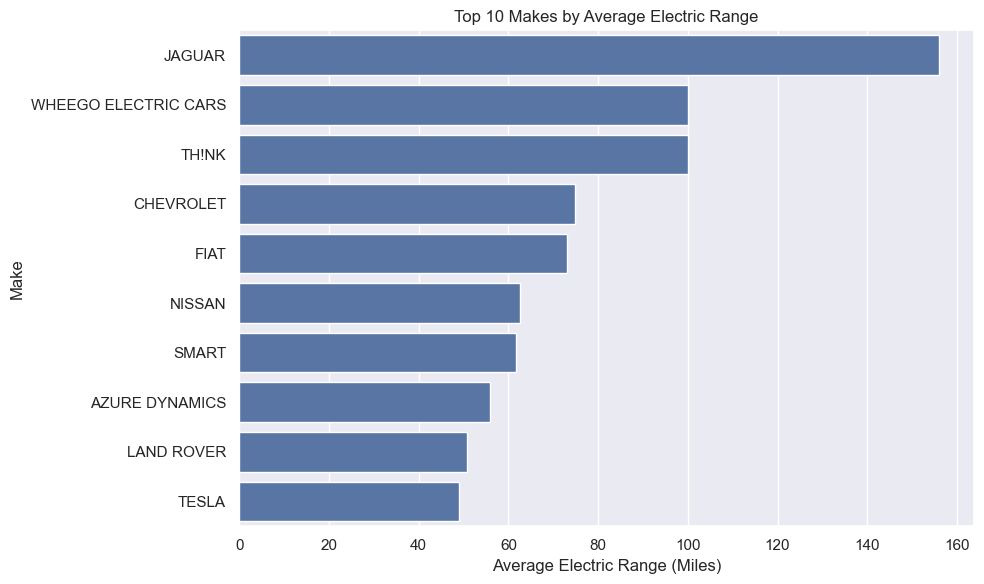

In [28]:
# Average Electric Range by Make
top_range_make = range_make.sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_range_make.values,
    y=top_range_make.index
)

plt.title("Top 10 Makes by Average Electric Range")
plt.xlabel("Average Electric Range (Miles)")
plt.ylabel("Make")

plt.tight_layout()
plt.show()

# 22. Analyzing Average Electric Range by Model

In [29]:
range_model = df.groupby('Model')['Electric Range'].mean()

print("Top 10 Models by Average Electric Range:")
print(range_model.sort_values(ascending=False).head(10))

Top 10 Models by Average Electric Range:
Model
ROADSTER    230.000000
BOLT EV     168.709497
MODEL S     158.704265
I-PACE      156.000000
E-TRON      121.525020
E-GOLF      107.708253
MODEL X     106.476358
RAV4        102.686275
WHEEGO      100.000000
CITY        100.000000
Name: Electric Range, dtype: float64


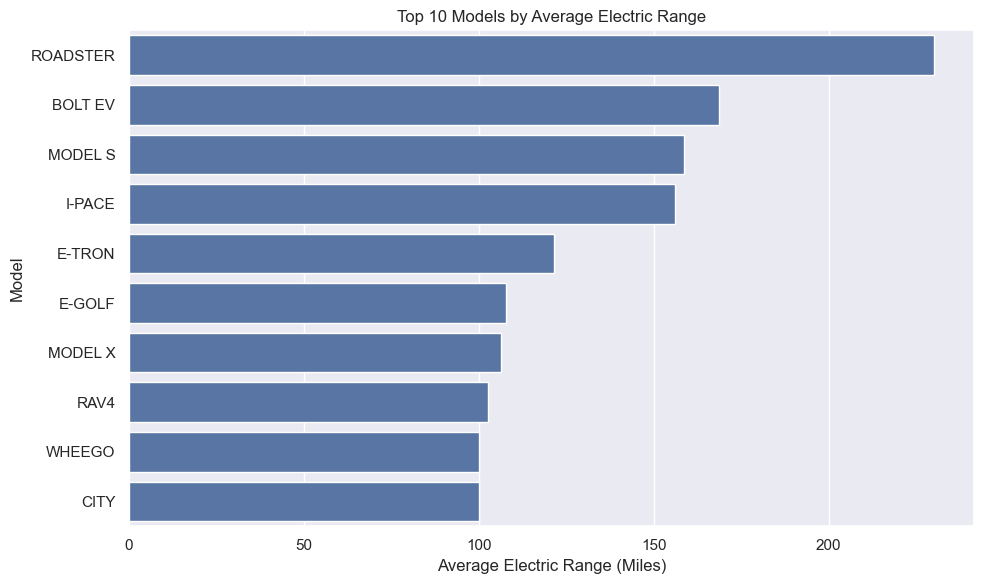

In [30]:
# Average Electric Range by Model
top_range_model = range_model.sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_range_model.values,
    y=top_range_model.index
)

plt.title("Top 10 Models by Average Electric Range")
plt.xlabel("Average Electric Range (Miles)")
plt.ylabel("Model")

plt.tight_layout()
plt.show()

# 23. Checking Base MSRP Availability

In [31]:
if 'Base MSRP' in df.columns:
    print(df.groupby('Model')['Base MSRP'].mean().sort_values(ascending=False).head(10))
else:
    print("Base MSRP column is not available in this dataset.")

Base MSRP column is not available in this dataset.


# 24. Visualizing the Top 5 EV Manufacturers

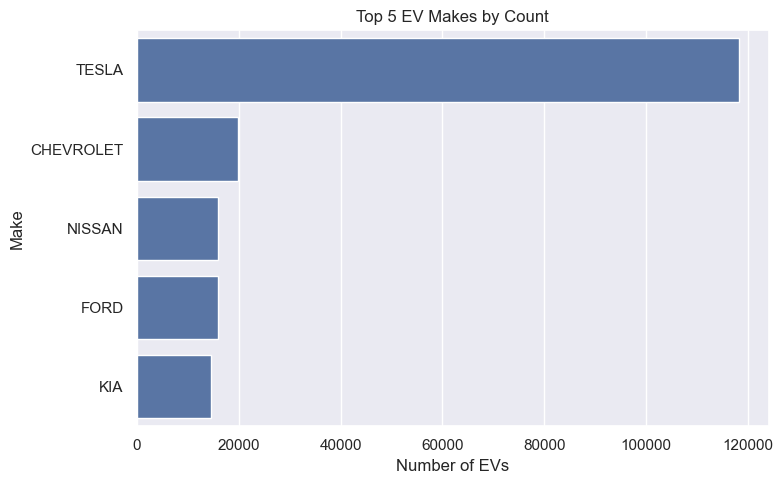

In [39]:
#Data Visualization

plt.figure(figsize=(8, 5))

sns.barplot(
    x=top_makes.values,
    y=top_makes.index
)

plt.title("Top 5 EV Makes by Count")
plt.xlabel("Number of EVs")
plt.ylabel("Make")

plt.tight_layout()
plt.show()

# 25. Visualizing the Top 5 EV Models

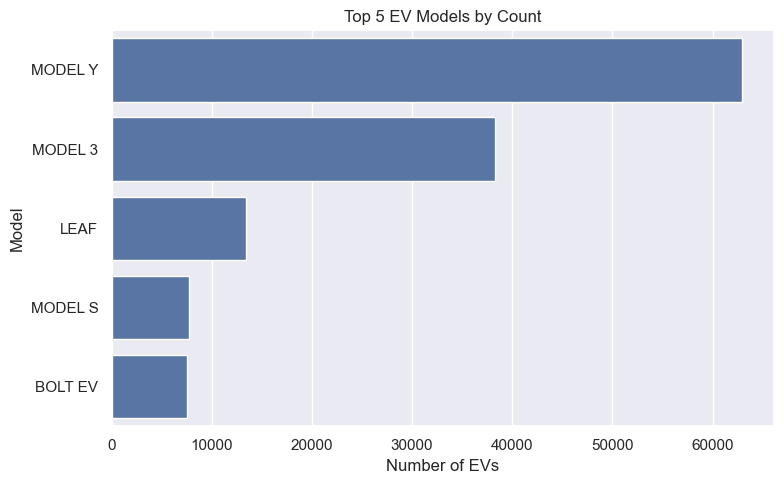

In [40]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=top_models.values,
    y=top_models.index
)

plt.title("Top 5 EV Models by Count")
plt.xlabel("Number of EVs")
plt.ylabel("Model")

plt.tight_layout()
plt.show()

# 26. Visualizing EV Registrations by County

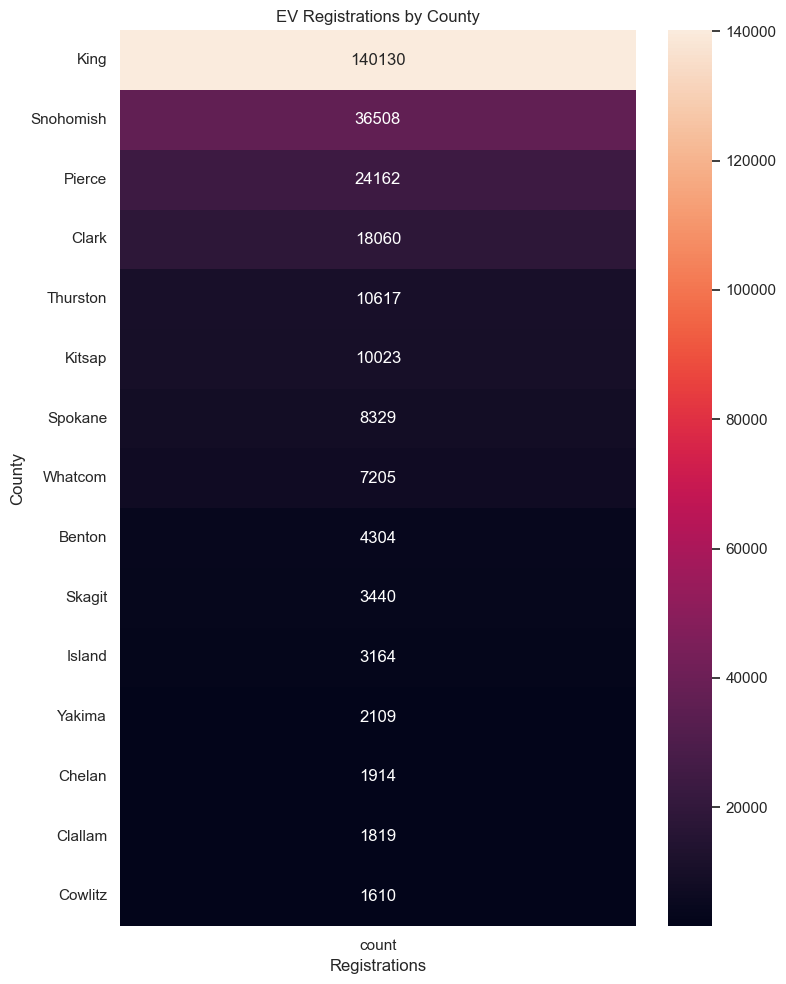

In [41]:
county = county_counts.head(15)

plt.figure(figsize=(8, 10))

sns.heatmap(
    county.to_frame(),
    annot=True,
    fmt='g'
)

plt.title("EV Registrations by County")
plt.xlabel("Registrations")
plt.ylabel("County")

plt.tight_layout()
plt.show()

# 27. Visualizing EV Adoption by Model Year

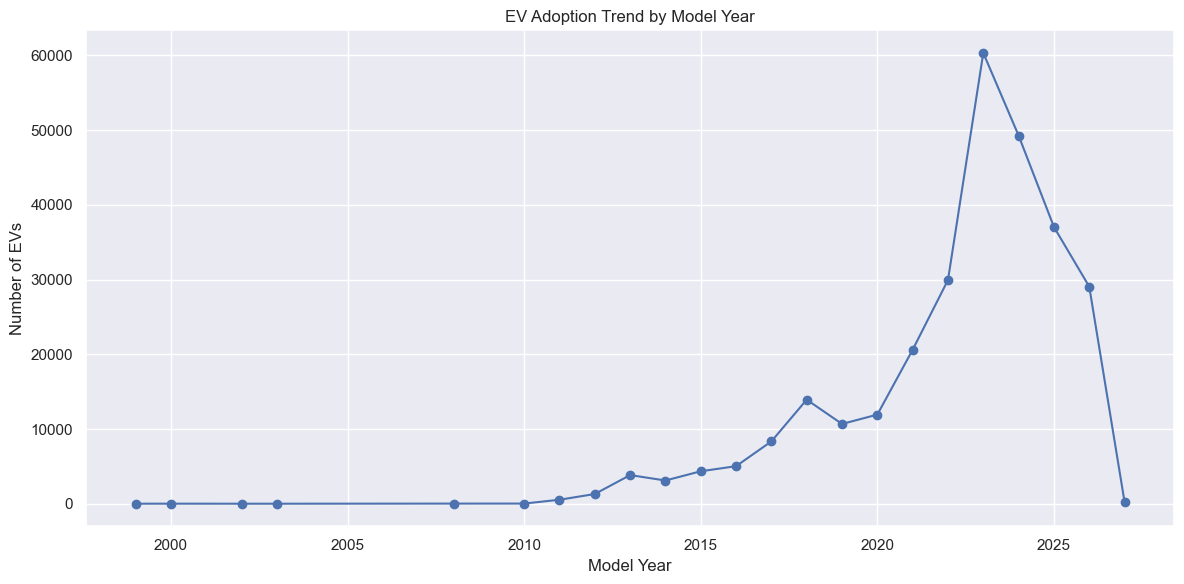

In [42]:
plt.figure(figsize=(12, 6))

plt.plot(
    year.index,
    year.values,
    marker='o'
)

plt.title("EV Adoption Trend by Model Year")
plt.xlabel("Model Year")
plt.ylabel("Number of EVs")

plt.grid(True)
plt.tight_layout()
plt.show()

# 28. Checking the Relationship Between Electric Range and Base MSRP

In [43]:
if 'Base MSRP' in df.columns:
    plt.figure(figsize=(8, 6))
    plt.scatter(df['Base MSRP'], df['Electric Range'])
    plt.title("Electric Range vs Base MSRP")
    plt.xlabel("Base MSRP")
    plt.ylabel("Electric Range (Miles)")
    plt.tight_layout()
    plt.show()
else:
    print("Base MSRP column is not available in this dataset.")

Base MSRP column is not available in this dataset.


# 29. Visualizing CAFV Eligibility Distribution

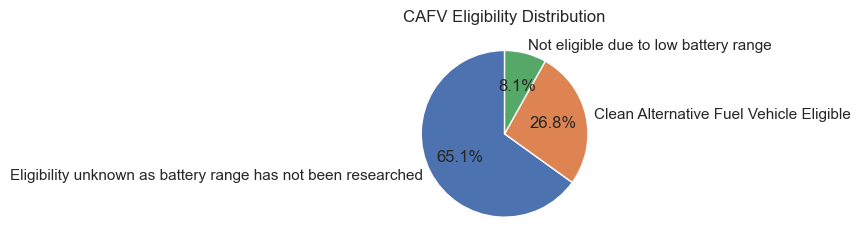

In [44]:
plt.figure(figsize=(8, 8))

plt.pie(
    cafv,
    labels=cafv.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title("CAFV Eligibility Distribution")

plt.tight_layout()
plt.show()

# 30. Visualizing EV Registrations by Vehicle Location

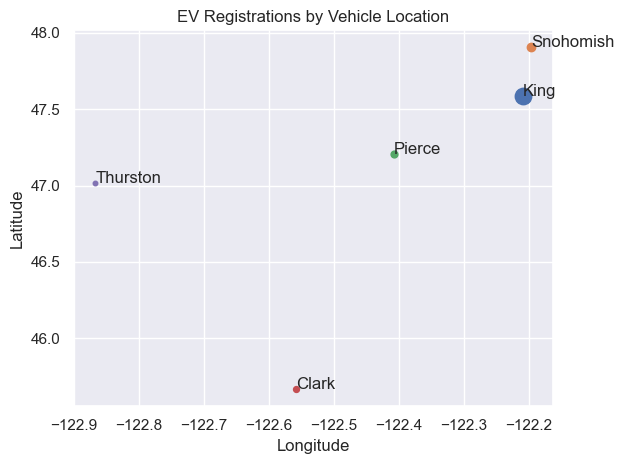

In [53]:
top_counties = df['County'].value_counts().head(5)

for county in top_counties.index:

    data = df[df['County'] == county]

    latitude = data['Latitude'].mean()
    longitude = data['Longitude'].mean()

    size = top_counties[county] / 1000

    plt.scatter(longitude, latitude, s=size)
    plt.text(longitude, latitude, county)

plt.title("EV Registrations by Vehicle Location")
plt.xlabel("Longitude")
plt.ylabel("Latitude")

plt.tight_layout()
plt.show()

# 31. Project Conclusion

In [54]:
print("Project Conclusion")
print("-" * 30)

print("The analysis explored EV registrations based on")
print("vehicle make, model, county, model year, electric range,")
print("CAFV eligibility, and vehicle location.")

print("\nKey findings:")
print("- Tesla has the highest number of EV registrations.")
print("- King County has the highest EV registrations.")
print("- EV registrations increased significantly in recent model years.")
print("- The average electric range is 37.4 miles.")
print("- Most records have unknown CAFV eligibility.")

Project Conclusion
------------------------------
The analysis explored EV registrations based on
vehicle make, model, county, model year, electric range,
CAFV eligibility, and vehicle location.

Key findings:
- Tesla has the highest number of EV registrations.
- King County has the highest EV registrations.
- EV registrations increased significantly in recent model years.
- The average electric range is 37.4 miles.
- Most records have unknown CAFV eligibility.
